# code_049 · Measurement units, timestamps and validity

**Book:** section 10.3. A self-contained data-cleaning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_10_GUIDE.md), [run evidence](../CHAPTER_10_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_049).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All data and calibration/measurement assumptions are simulated, without field safety, causal or universal cleaning claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1049;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1049


<a id="units"></a>
## Convert quantities, not just column names

Raw displacement records have values 1.2 mm, .0014 m, 1500 micrometres and -.8 mm. Signed displacement permits the negative value. A separate length record -2 m violates this fixture's positive-length schema and is held for review; it must not be mixed into displacement summaries. Source units determine conversion factors, and the raw payload remains intact. The .0014-m record is 1.4 mm, not a small-displacement anomaly. No statistical scaler is allowed to repair unknown physical units.


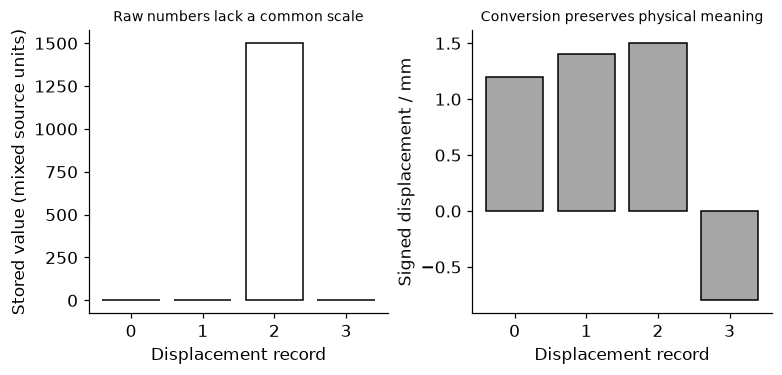

In [2]:
raw=pd.DataFrame({'record_id':range(5),'quantity':['displacement']*4+['length'],'value':[1.2,.0014,1500.,-.8,-2.],'unit':['mm','m','um','mm','m']})
factor={'mm':1.,'m':1000.,'um':.001};converted=raw.value.to_numpy()*raw.unit.map(factor).to_numpy();valid=(raw.quantity=='displacement').to_numpy()
assert np.allclose(converted[:4],[1.2,1.4,1.5,-.8]) and raw.value.iloc[1]==.0014
assert converted[3]<0 and valid[3] and not valid[4] and raw.value.iloc[4]<0
assert raw.record_id.is_unique and set(raw.unit)<=set(factor)
fig,axes=plt.subplots(1,2,figsize=(7,3.3));axes[0].bar(np.arange(4),raw.value.iloc[:4],color='white',edgecolor='black');axes[0].set(xlabel='Displacement record',ylabel='Stored value (mixed source units)',title='Raw numbers lack a common scale');axes[1].bar(np.arange(4),converted[:4],color='.65',edgecolor='black');axes[1].set(xlabel='Displacement record',ylabel='Signed displacement / mm',title='Conversion preserves physical meaning');[a.title.set_fontsize(9) for a in axes];plt.show()
RESULTS['canonical_displacements_mm']=converted[:4].tolist();RESULTS['invalid_length_records']=1


<a id="clocks"></a>
## The same local clock reading can denote two instants

Two offset-aware records read 02:30 on 5 April 2026, one with +11:00 and one +10:00. They are an hour apart in UTC. These offsets correspond to the repeated local hour in this fixture's Australia/Melbourne conversion, verified against the installed timezone database. A naive local string loses the distinction. Preserve the offset/zone, normalize to UTC for ordering and retain the source display context. A separate arrival-before-event fixture is rejected for review rather than silently reordering clocks.


In [3]:
from zoneinfo import ZoneInfo
aware=pd.to_datetime(['2026-04-05T02:30:00+11:00','2026-04-05T02:30:00+10:00'],utc=True)
assert (aware[1]-aware[0]).total_seconds()==3600
local=[d.to_pydatetime().astimezone(ZoneInfo('Australia/Melbourne')) for d in aware]
assert local[0].hour==local[1].hour==2 and local[0].fold==0 and local[1].fold==1
assert local[0].utcoffset()!=local[1].utcoffset()
event=pd.Timestamp('2026-01-01T10:00:00Z');arrival=pd.Timestamp('2026-01-01T09:59:00Z');assert arrival<event
RESULTS['same_local_clock_UTC_gap_seconds']=3600;RESULTS['timezone_folds']=[d.fold for d in local];RESULTS['arrival_before_event_flagged']=True


<a id="calibration"></a>
## Calibration uses independent reference evidence

A known sensor mechanism is raw_mm=1.05*reference_mm+.20+noise sd .005 mm. Ten reference standards spanning 0–3 mm estimate gain and offset before any operational model fitting. Five fresh standards then check the frozen calibration. This is an independent numerical check under the simulator, not laboratory accreditation or field validity. Apply unit conversion before the calibration expressed in mm. Fitting the correction to future target outcomes would be a different and potentially leaking procedure.


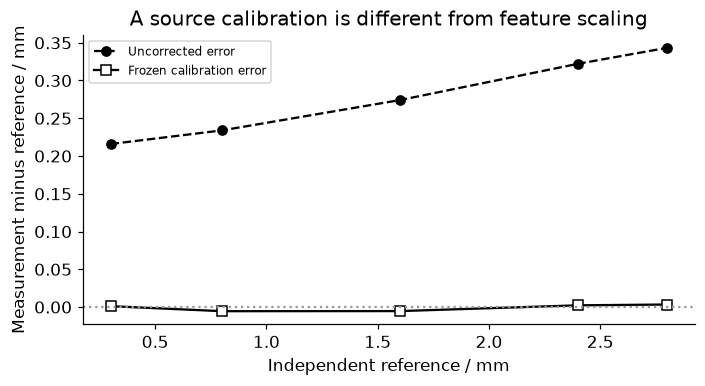

In [4]:
standards=np.linspace(0,3,10);sensor=1.05*standards+.2+rng.normal(0,.005,10)
X=np.column_stack([np.ones(10),standards]);offset,gain=np.linalg.lstsq(X,sensor,rcond=None)[0];assert gain>0
check=np.array([.3,.8,1.6,2.4,2.8]);new_raw=1.05*check+.2+rng.normal(0,.005,5);corrected=(new_raw-offset)/gain
raw_mae=float(np.mean(abs(new_raw-check)));corrected_mae=float(np.mean(abs(corrected-check)))
assert corrected_mae<raw_mae and np.isfinite(corrected).all()
in_m=new_raw/1000;assert np.allclose((in_m*1000-offset)/gain,corrected)
fig,ax=plt.subplots(figsize=(6.3,3.4));ax.plot(check,new_raw-check,'ko--',label='Uncorrected error');ax.plot(check,corrected-check,'ks-',mfc='white',label='Frozen calibration error');ax.axhline(0,color='.6',ls=':');ax.set(xlabel='Independent reference / mm',ylabel='Measurement minus reference / mm',title='A source calibration is different from feature scaling');ax.legend(fontsize=8);plt.show()
RESULTS['estimated_calibration']={'offset_mm':float(offset),'gain':float(gain)};RESULTS['independent_standard_MAE_mm']={'raw':raw_mae,'calibrated':corrected_mae}


<a id="exercises"></a>
## Exercises and hints

1. Remove the source-unit tag and explain why a plausible number alone cannot certify its unit.
2. Add a timezone-naive repeated-hour record and require an explicit disambiguation policy.
3. Simulate gain drift after calibration; use fresh reference checks rather than refitting on final targets.
4. Specify valid ranges separately for signed force, positive length and a bounded probability.

**Hints:** timestamps, quantity semantics, calibration revision and raw lineage precede statistical standardization. Clock skew can require investigation, not a guessed timestamp repair. See the official [zoneinfo](https://docs.python.org/3/library/zoneinfo.html) interface; the executed Python is 3.14.3 and the live docs may advance.


In [5]:
summary={'example_id':'code_049','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['quantity-aware unit conversion', 'offset-aware timestamp ordering and repeated local clocks', 'event-arrival validity checks', 'independent reference calibration', 'schema checks precede statistical scaling'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["quantity-aware unit conversion", "offset-aware timestamp ordering and repeated local clocks", "event-arrival validity checks", "independent reference calibration", "schema checks precede statistical scaling"], "elapsed_seconds": 0.14, "example_id": "code_049", "hardware": "Darwin arm64 CPU", "results": {"arrival_before_event_flagged": true, "canonical_displacements_mm": [1.2, 1.4, 1.5, -0.8], "estimated_calibration": {"gain": 1.0500494947212786, "offset_mm": 0.19968269207721817}, "independent_standard_MAE_mm": {"calibrated": 0.003511266914833733, "raw": 0.2778523843817003}, "invalid_length_records": 1, "same_local_clock_UTC_gap_seconds": 3600, "timezone_folds": [0, 1]}, "seed": 1049, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
